# Modelo de Floresta Aleatória

## Importações inicias

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [135]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.datasets import load_iris, load_breast_cancer

## Implementação bruta

### Implementação do modelo de árvore de decisão

A implementação da classe `DecisionTree` a seguir foi feita em outra atividade, a atividade de Árvores de decisão. 

In [136]:
class DecisionTree:
    class Node:
        def __init__(self, feature=None, threshold=None, left=None, right=None, prediction=None):
            self.feature = feature
            self.threshold = threshold
            self.left = left
            self.right = right
            self.prediction = prediction

    def __init__(self, max_depth=None, min_samples_split=2, random_state=0):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.random_state = random_state
        self.root = None
        self.n_classes_ = None
        self.n_features_in_ = None

    @staticmethod
    def _gini(y):
        if len(y) == 0:
            return 0.0
        _, counts = np.unique(y, return_counts=True)
        probabilities = counts / len(y)
        return 1.0 - np.sum(probabilities ** 2)

    def _majority_class(self, y):
        classes, counts = np.unique(y, return_counts=True)
        return classes[np.argmax(counts)]

    def _best_split(self, X, y):
        best_gini = self._gini(y)
        best_feature = None
        best_threshold = None
        n_samples, n_features = X.shape

        for feature in range(n_features):
            values = np.unique(X[:, feature])
            if len(values) <= 1:
                continue
            thresholds = (values[:-1] + values[1:]) / 2

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask
                if not left_mask.any() or not right_mask.any():
                    continue

                left_gini = self._gini(y[left_mask])
                right_gini = self._gini(y[right_mask])
                weighted_gini = (
                    left_mask.sum() * left_gini + right_mask.sum() * right_gini
                ) / n_samples

                if weighted_gini < best_gini:
                    best_gini = weighted_gini
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold

    def _grow_tree(self, X, y, depth):
        prediction = self._majority_class(y)
        node = self.Node(prediction=prediction)

        is_pure = len(np.unique(y)) == 1
        reached_depth = self.max_depth is not None and depth >= self.max_depth
        too_few_samples = len(y) < self.min_samples_split
        if is_pure or reached_depth or too_few_samples:
            return node

        feature, threshold = self._best_split(X, y)
        if feature is None:
            return node

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask
        node.feature = feature
        node.threshold = threshold
        node.left = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
        node.right = self._grow_tree(X[right_mask], y[right_mask], depth + 1)
        return node

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        if X.ndim != 2:
            raise ValueError("X deve ser uma matriz bidimensional.")
        if y.ndim != 1 or len(X) != len(y):
            raise ValueError("X e y devem ter o mesmo número de amostras.")
        if self.min_samples_split < 2:
            raise ValueError("min_samples_split deve ser pelo menos 2.")

        self.n_features_in_ = X.shape[1]
        self.n_classes_ = np.unique(y)
        self.root = self._grow_tree(X, y, depth=0)
        return self

    def _predict_one(self, sample, node):
        if node.left is None and node.right is None:
            return node.prediction
        if sample[node.feature] <= node.threshold:
            return self._predict_one(sample, node.left)
        return self._predict_one(sample, node.right)

    def predict(self, X):
        if self.root is None:
            raise ValueError("O modelo precisa ser ajustado com fit antes de predict.")
        X = np.asarray(X)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError("X deve ter o mesmo número de atributos usado em fit.")
        return np.array([self._predict_one(sample, self.root) for sample in X])

class RandomForestTree(DecisionTree):
    def __init__(self, max_depth=None, min_samples_split=2, max_features="sqrt", random_state=None):
        super().__init__(max_depth=max_depth, min_samples_split=min_samples_split, random_state=random_state)
        self.max_features = max_features

    def _best_split(self, X, y):
        n_samples, n_features = X.shape

        if self.max_features == "sqrt":
            n_feat_to_select = max(1, int(np.sqrt(n_features)))
        elif self.max_features == "log":
            n_feat_to_select = max(1, int(np.log2(n_features)))
        elif isinstance(self.max_features, int):
            n_feat_to_select = min(self.max_features, n_features)
        elif isinstance(self.max_features, float):
            n_feat_to_select = max(1, int(self.max_features * n_features))
        else:
            n_feat_to_select = n_features

        feature_indices = np.random.choice(n_features, n_feat_to_select, replace=False)

        best_gini = self._gini(y)
        best_feature = None
        best_threshold = None

        for feature in feature_indices:
            values = np.unique(X[:, feature])
            if len(values) <= 1:
                continue
            thresholds = (values[:-1] + values[1:]) / 2

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask
                if not left_mask.any() or not right_mask.any():
                    continue

                left_gini = self._gini(y[left_mask])
                right_gini = self._gini(y[right_mask])
                weighted_gini = (
                    left_mask.sum() * left_gini + right_mask.sum() * right_gini
                ) / n_samples

                if weighted_gini < best_gini:
                    best_gini = weighted_gini
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold

### Implementação da classe de Florestas aleatórias

In [137]:
class RandomForest:
    """Classificador de Floresta Aleatória (Random Forest)."""
    def __init__(self, n_estimators=100, max_depth=None, min_samples_split=2, max_features="sqrt", random_state=0):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.random_state = random_state
        self.trees = []
        self.n_classes_ = None
        self.n_features_in_ = None

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        
        if X.ndim != 2:
            raise ValueError("X deve ser uma matriz bidimensional.")
        if y.ndim != 1 or len(X) != len(y):
            raise ValueError("X e y devem ter o mesmo número de amostras.")

        self.n_features_in_ = X.shape[1]
        self.n_classes_ = np.unique(y)
        self.trees = []

        if self.random_state is not None:
            np.random.seed(self.random_state)

        n_samples = X.shape[0]

        for _ in range(self.n_estimators):
            indices = np.random.choice(n_samples, size=n_samples, replace=True)
            X_bootstrap = X[indices]
            y_bootstrap = y[indices]
            
            tree = RandomForestTree(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                max_features=self.max_features
            )
            tree.fit(X_bootstrap, y_bootstrap)
            self.trees.append(tree)

        return self

    def predict(self, X):
        if not self.trees:
            raise ValueError("O modelo precisa ser ajustado com fit antes de predict.")
        
        X = np.asarray(X)
        if X.ndim == 1:
            X = X.reshape(1, -1)
            
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError("X deve ter o mesmo número de atributos usado em fit.")

        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        tree_preds = tree_preds.T

        final_preds = []
        for preds in tree_preds:
            classes, counts = np.unique(preds, return_counts=True)
            majority_class = classes[np.argmax(counts)]
            final_preds.append(majority_class)

        return np.array(final_preds)

## Modelagem com o dataset Iris

### Divisão

In [138]:
X, y = load_iris(as_frame=True, return_X_y=True)

In [139]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=0,test_size=0.2)

### Modelo Bruto

In [140]:
rf = RandomForest()

In [141]:
rf.fit(X_train,y_train)

Na minha implementação foram 2.7 segundos, como não fica salvo no notebook então vou registrar via markdown mesmo

In [142]:
y_pred = rf.predict(X_test)

In [143]:
df_metrics = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred), precision_score(y_test,y_pred,average="weighted"), recall_score(y_test,y_pred,average="weighted"), f1_score(y_test,y_pred,average="weighted")],
    index=["Acurácia", "Precisão", "Recall", "F1-score"],
    columns=["RandomForest_Iris"]
)

### Modelo scikit-learn

In [144]:
rf = RandomForestClassifier()

In [145]:
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Na implementação do Sciki-Learn foram 0.9 segundos.

In [146]:
y_pred = rf.predict(X_test)

In [147]:
df = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred,average="weighted"),recall_score(y_test,y_pred,average="weighted"),f1_score(y_test,y_pred,average="weighted")],
    index=["Acurácia", "Precisão", "Recall", "F1-score"],
    columns=["RandomForestSK_Iris"]
)

In [148]:
df_metrics = pd.concat([df_metrics,df],axis=1)

## Modelagem com Breast Cancer

### Divisão

In [149]:
X, y = load_breast_cancer(as_frame=True, return_X_y=True)

In [150]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.2, random_state=0)

### Modelo Bruto

In [151]:
rf = RandomForest(random_state=0)

In [152]:
rf.fit(X_train,y_train)

Na minha implementação foram 6.6 segundos, como não fica salvo no notebook então vou registrar via markdown mesmo

In [153]:
y_pred = rf.predict(X_test)

In [154]:
df = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred),f1_score(y_test,y_pred)],
    index=["Acurácia", "Precisão", "Recall", "F1-score"],
    columns=["RandomForest_BreastCancer"]
)

In [155]:
df_metrics = pd.concat([df_metrics,df],axis=1)

### Modelo Scikit-learn

In [156]:
rf = RandomForestClassifier(random_state=0)

In [157]:
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Na implementação do Sciki-Learn foram 0.4 segundos.

In [158]:
y_pred = rf.predict(X_test)

In [159]:
df = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred,average="weighted"),recall_score(y_test,y_pred,average="weighted"),f1_score(y_test,y_pred,average="weighted")],
    index=["Acurácia", "Precisão", "Recall", "F1-score"],
    columns=["RandomForestSK_BreastCancer"]
)

In [160]:
df_metrics = pd.concat([df_metrics,df],axis=1)

In [161]:
df_metrics

,RandomForest_Iris,RandomForestSK_Iris,RandomForest_BreastCancer,RandomForestSK_BreastCancer
Acurácia,1.0,1.0,0.932018,0.936404
Precisão,1.0,1.0,0.926667,0.936648
Recall,1.0,1.0,0.968641,0.936404
F1-score,1.0,1.0,0.947189,0.935932


Como todas as métricas ficaram maximizadas no Iris, então irei fazer tunagem de hiperparâmetros apenas no BreastCancer

## Busca por hiperparâmetros usando `GridSearchCV`

In [162]:
criterion = ["gini","entropy","log_loss"]
max_features = ["sqrt","log2"]
max_depth = [15, 30, 50, 100]

In [163]:
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),
    param_grid={
        "criterion": criterion,
        "max_features": max_features,
        "max_depth": max_depth
    },
    n_jobs=1,
    cv=5,
    verbose=1
)

In [164]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...andom_state=0)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy', ...], 'max_depth': [15, 30, ...], 'max_features': ['sqrt', 'log2']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed

In [165]:
print("Melhores hiperparâmetros encontrados:", grid_search.best_params_)

Melhores hiperparâmetros encontrados: {'criterion': 'entropy', 'max_depth': 15, 'max_features': 'sqrt'}


In [166]:
y_pred = grid_search.predict(X_test)

In [167]:
df = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred,average="weighted"),recall_score(y_test,y_pred,average="weighted"),f1_score(y_test,y_pred,average="weighted")],
    index=["Acurácia", "Precisão", "Recall", "F1-score"],
    columns=["DecisionTreeClassifierSK_BreastCancer"]
)

In [168]:
df_metrics = pd.concat([df_metrics,df],axis=1)

In [169]:
df_metrics

,RandomForest_Iris,RandomForestSK_Iris,RandomForest_BreastCancer,RandomForestSK_BreastCancer,DecisionTreeClassifierSK_BreastCancer
Acurácia,1.0,1.0,0.932018,0.936404,0.914474
Precisão,1.0,1.0,0.926667,0.936648,0.915209
Recall,1.0,1.0,0.968641,0.936404,0.914474
F1-score,1.0,1.0,0.947189,0.935932,0.913439


Como podemos ver acima, o melhor modelo com as melhores métricas é o de floresta aleatória bruto. Portanto ele é o modelo vencedor para o dataset BreastCancer.

## Visualização das árvores

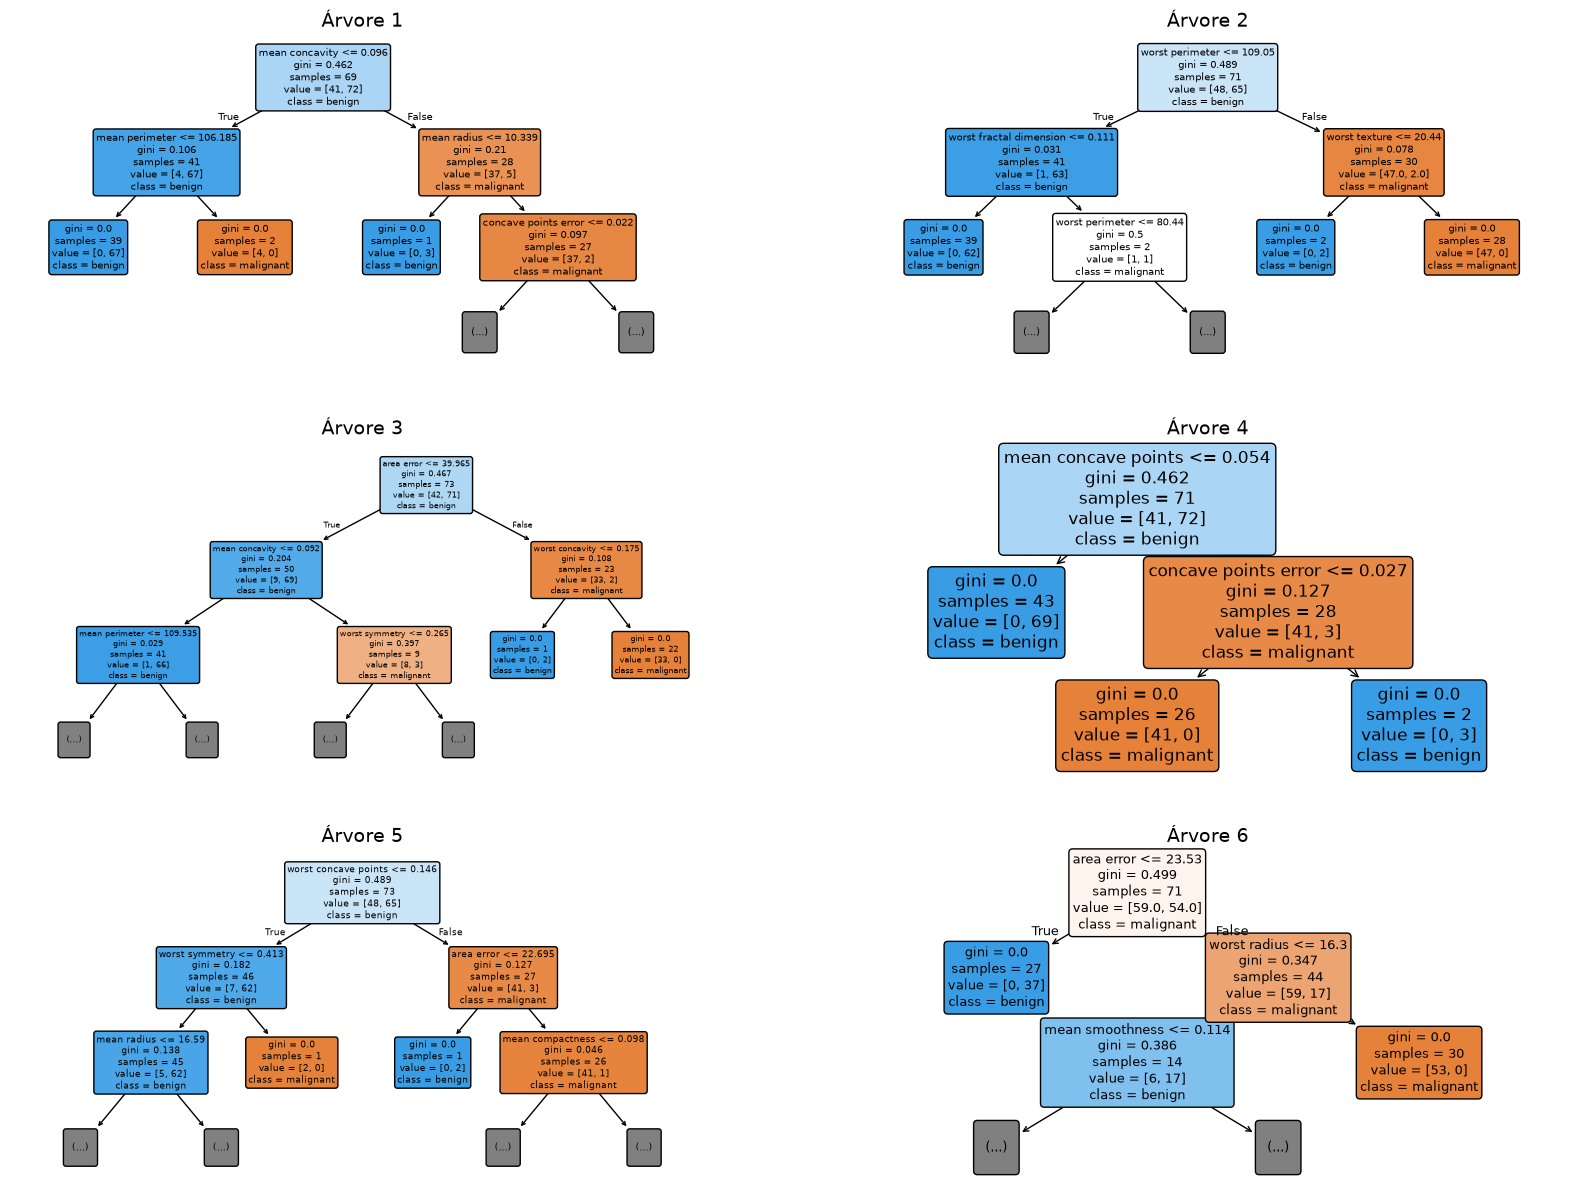

In [170]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 15))

axes_flat = axes.flatten()

for index in range(6):
    plot_tree(
        rf.estimators_[index],
        feature_names=load_breast_cancer().feature_names,
        class_names=[str(c) for c in load_breast_cancer().target_names],
        filled=True,
        rounded=True,
        max_depth=2,
        ax=axes_flat[index],
    )
    axes_flat[index].set_title(f"Árvore {index + 1}", fontsize=14)

plt.show()